# 06 · MLP dự đoán PM2.5 giờ kế tiếp

Notebook bổ sung **MLP (mạng nơ-ron nhiều lớp)** cho bài toán hồi quy. Mỗi dòng đầu vào mô tả một trạm tại giờ hiện tại và các giờ trước. Đầu ra là một số liên tục, tính bằng µg/m³, cho cùng trạm ở giờ kế tiếp.

Đặt notebook trong thư mục `notebooks/` của đồ án và chạy lần lượt các ô. Notebook dùng lại 27 đặc trưng đầu vào, 5 lượt validation theo thời gian và ba chỉ số MAE, RMSE, R² của nhóm. Cấu hình MLP bên dưới là cấu hình thử ban đầu. Các kết quả ở đây đều là kết quả validation.

## 1. Nạp thư viện và dùng lại mã chung

Dùng các hàm trong `src/` để MLP nhận cùng dữ liệu và dùng cùng cách chia như Random Forest và Gradient Boosting. Tham số `SAVE_ARTIFACTS` ở đầu ô cuối có thể bật khi cần lưu kết quả và mô hình.

In [1]:
import json
import sys
import time
import warnings
from io import BytesIO
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Image, display
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

current_dir = Path.cwd().resolve()
project_root = next(
    (path for path in (current_dir, *current_dir.parents) if (path / "src").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Hãy mở notebook từ thư mục đồ án hoặc thư mục notebooks.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_loader import TEST_START, cv_folds, load_data, time_split
from src.features import add_features, build_preprocessor, split_xy

print("scikit-learn", sklearn.__version__)

scikit-learn 1.7.2


## 2. Chuẩn bị X, y và 5 lượt validation

`X` gồm 27 cột đặc trưng. `y` là số đo PM2.5 thật ở giờ kế tiếp. Những dòng thiếu số đo thật được bỏ vì chương trình cần đáp án để chấm dự báo.

Mỗi fold huấn luyện trên các giờ sớm hơn rồi dự báo các giờ sau đó. Các trạm có cùng thời điểm nhãn được xếp cùng phía khi chia. Mốc test giữ theo notebook trước.

In [2]:
featured = add_features(load_data())
labeled = featured.dropna(subset=["target"]).reset_index(drop=True)
train_validation, test = time_split(labeled)
train_validation = train_validation.reset_index(drop=True)

X_tv, y_tv = split_xy(train_validation)
folds = cv_folds(train_validation, n_splits=5)
target_times = train_validation["target_datetime"]

assert target_times.max() < TEST_START <= test["target_datetime"].min()
for train_idx, val_idx in folds:
    assert target_times.iloc[train_idx].max() < target_times.iloc[val_idx].min()

print(f"Train và validation: {len(X_tv):,} mẫu, {X_tv.shape[1]} cột.")
print(f"Test giữ riêng: {len(test):,} mẫu.")
print(f"Số fold: {len(folds)}.")

Train và validation: 360,954 mẫu, 27 cột.
Test giữ riêng: 51,063 mẫu.
Số fold: 5.


## 3. Khởi tạo MLP

Hai lớp ẩn có 64 và 32 nơ-ron. Hàm ReLU giúp mạng học quan hệ phi tuyến, còn Adam cập nhật trọng số theo từng lô. Đây là một cấu hình cố định để có kết quả MLP ban đầu.

Bộ tiền xử lý học trung vị, cách mã hóa trạm/hướng gió và cách chuẩn hóa các cột số từ phần train của từng fold. Chuẩn hóa đưa các cột số về thang đo gần nhau để MLP dễ tối ưu. `TransformedTargetRegressor` cũng chuẩn hóa `y_train` trong lúc học và đổi dự báo về µg/m³ trước khi chấm.

MLP được giữ cấu hình cố định qua 5 fold. `early_stopping=False` giữ việc chấm validation theo cách chia thời gian của nhóm. Bộ tối ưu vẫn có thể dừng khi mức cải thiện của loss trên phần train quá nhỏ.

In [3]:
mlp_params = {
    "hidden_layer_sizes": (64, 32),
    "activation": "relu",
    "solver": "adam",
    "alpha": 0.001,
    "batch_size": 512,
    "learning_rate_init": 0.001,
    "max_iter": 60,
    "tol": 0.0002,
    "n_iter_no_change": 8,
    "early_stopping": False,
    "random_state": 42,
}


def make_mlp():
    return Pipeline([
        ("preprocess", build_preprocessor(scale=True)),
        ("model", TransformedTargetRegressor(
            regressor=MLPRegressor(**mlp_params),
            transformer=StandardScaler(),
        )),
    ])


def regression_metrics(y_true, y_pred):
    return {
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
        "r2": r2_score(y_true, y_pred),
    }

## 4. Huấn luyện và chấm trên từng fold

Tạo pipeline mới cho từng fold để bộ tiền xử lý và mạng nơ-ron học từ đúng phần train của lượt đó. Gọi `predict(X_val)` để dự báo, rồi so với `y_val`. Cột `hit_iteration_limit` cho biết lượt nào đã chạm giới hạn số vòng học trước khi hội tụ theo tiêu chí của bộ tối ưu.

In [4]:
fold_results = []
validation_predictions = []

for fold_id, (train_idx, val_idx) in enumerate(folds, start=1):
    X_train, y_train = X_tv.iloc[train_idx], y_tv.iloc[train_idx]
    X_val, y_val = X_tv.iloc[val_idx], y_tv.iloc[val_idx]
    model = make_mlp()
    started = time.perf_counter()

    with threadpool_limits(limits=1):
        with warnings.catch_warnings(record=True) as fit_warnings:
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(X_train, y_train)
        y_pred = model.predict(X_val)
        train_pred = model.predict(X_train)

    for warning in fit_warnings:
        if not issubclass(warning.category, ConvergenceWarning):
            warnings.warn(warning.message, warning.category)

    fold_predictions = train_validation.iloc[val_idx][
        ["station", "datetime", "target_datetime"]
    ].reset_index(drop=True).copy()
    fold_predictions.insert(0, "fold", fold_id)
    fold_predictions["y_true"] = y_val.to_numpy()
    fold_predictions["y_pred"] = y_pred
    validation_predictions.append(fold_predictions)
    scores = regression_metrics(y_val, y_pred)
    fold_results.append({
        "fold": fold_id,
        **scores,
        "train_rmse": np.sqrt(mean_squared_error(y_train, train_pred)),
        "runtime_seconds": time.perf_counter() - started,
        "train_rows": len(train_idx),
        "validation_rows": len(val_idx),
        "epochs": model.named_steps["model"].regressor_.n_iter_,
        "hit_iteration_limit": any(
            issubclass(warning.category, ConvergenceWarning) for warning in fit_warnings
        ),
    })
    print(f"Fold {fold_id} | RMSE = {scores['rmse']:.4f}")

mlp_cv_metrics = pd.DataFrame(fold_results)
mlp_oof = pd.concat(validation_predictions, ignore_index=True)
mlp_oof["residual"] = mlp_oof["y_true"] - mlp_oof["y_pred"]
mlp_cv_metrics["rmse_gap"] = mlp_cv_metrics["rmse"] - mlp_cv_metrics["train_rmse"]
mlp_cv_metrics["rmse_ratio"] = mlp_cv_metrics["rmse"] / mlp_cv_metrics["train_rmse"]
display(mlp_cv_metrics.round(4))

Fold 1 | RMSE = 28.0582
Fold 2 | RMSE = 16.6027
Fold 3 | RMSE = 19.4096
Fold 4 | RMSE = 18.6658
Fold 5 | RMSE = 17.6836


,fold,mae,rmse,r2,train_rmse,runtime_seconds,train_rows,validation_rows,epochs,hit_iteration_limit,rmse_gap,rmse_ratio
0,1,17.8357,28.0582,0.9053,15.3116,8.5529,60258,60595,60,True,12.7466,1.8325
1,2,10.2748,16.6027,0.9457,16.9929,14.4395,120853,59958,53,False,-0.3902,0.9770
2,3,11.1442,19.4096,0.9280,16.7177,16.5576,180811,59858,26,False,2.6919,1.1610
3,4,10.3476,18.6658,0.9595,16.6600,38.4377,240669,60217,31,False,2.0057,1.1204
4,5,9.0384,17.6836,0.9185,16.9483,24.3027,300886,60068,22,False,0.7353,1.0434


## 5. So sánh với các mô hình đã chạy

MAE đo độ lệch tuyệt đối trung bình. RMSE nhạy hơn với sai số lớn. Hai chỉ số này càng thấp càng tốt. R² càng cao càng tốt. Cách tổng hợp lấy trung bình điểm của 5 fold như các notebook trước. Bảng chỉ lấy các kết quả validation từ `experiment_log.csv` để so với MLP.

In [5]:
metric_columns = ["mae", "rmse", "r2"]
mlp_cv_summary = (
    mlp_cv_metrics[metric_columns].agg(["mean", "std"]).T
    .rename_axis("metric").reset_index()
)
display(mlp_cv_summary.round(4))

experiment_log = project_root / "experiment_log.csv"
log = pd.read_csv(experiment_log)
comparison_columns = ["model_name", *metric_columns]
existing_cv = log.loc[
    log["experiment_id"].str.endswith("_cv5") & log["experiment_id"].ne("mlp_cv5"),
    comparison_columns,
]
mlp_scores = mlp_cv_metrics[metric_columns].mean().to_dict()
comparison = pd.concat(
    [existing_cv, pd.DataFrame([{"model_name": "MLP", **mlp_scores}])],
    ignore_index=True,
).sort_values("rmse").reset_index(drop=True)
display(comparison.round(4))

,metric,mean,std
0,mae,11.7282,3.4963
1,rmse,20.0840,4.5808
2,r2,0.9314,0.0215


,model_name,mae,rmse,r2
0,Random Forest Regressor - tuned,10.1254,19.1779,0.9377
1,Linear Regression,10.7380,19.2950,0.9363
2,Persistence,10.4240,19.9665,0.9318
3,Gradient Boosting Regressor (HistGradientBoost...,10.5222,20.0384,0.9328
4,MLP,11.7282,20.0840,0.9314
5,Random Forest Regressor,10.5256,20.1707,0.9309
6,Gradient Boosting Regressor (HistGradientBoost...,11.0743,21.9726,0.9173


## 6. Kiểm tra học vẹt (overfitting)

Cùng một mô hình của mỗi fold được chấm trên hai phần. **RMSE train** đo sai số trên dữ liệu mô hình đã học. **RMSE validation** đo sai số trên giai đoạn nằm sau phần train. Tỉ lệ của hai số càng lớn thì khoảng cách càng đáng chú ý. Chênh lệch có thể đến từ học vẹt hoặc từ sự thay đổi dữ liệu giữa hai giai đoạn, chẳng hạn khác mùa. Xem thêm mốc thời gian khi đọc bảng.

In [6]:
fold_periods = pd.DataFrame([
    {
        "fold": fold_id,
        "train_start": target_times.iloc[train_idx].min(),
        "train_end": target_times.iloc[train_idx].max(),
        "validation_start": target_times.iloc[val_idx].min(),
        "validation_end": target_times.iloc[val_idx].max(),
    }
    for fold_id, (train_idx, val_idx) in enumerate(folds, start=1)
])

overfit = mlp_cv_metrics[["fold", "train_rmse", "rmse", "rmse_gap", "rmse_ratio"]]
display(overfit.rename(columns={
    "train_rmse": "RMSE train",
    "rmse": "RMSE validation",
    "rmse_gap": "Validation − train",
    "rmse_ratio": "Validation / train",
}).round(3))
display(fold_periods)

,fold,RMSE train,RMSE validation,Validation − train,Validation / train
0,1,15.312,28.058,12.747,1.832
1,2,16.993,16.603,-0.390,0.977
2,3,16.718,19.410,2.692,1.161
3,4,16.660,18.666,2.006,1.120
4,5,16.948,17.684,0.735,1.043


,fold,train_start,train_end,validation_start,validation_end
0,1,2013-03-01 01:00:00,2013-09-30 00:00:00,2013-09-30 01:00:00,2014-05-01 17:00:00
1,2,2013-03-01 01:00:00,2014-05-01 17:00:00,2014-05-01 18:00:00,2014-11-30 16:00:00
2,3,2013-03-01 01:00:00,2014-11-30 16:00:00,2014-11-30 17:00:00,2015-07-02 02:00:00
3,4,2013-03-01 01:00:00,2015-07-02 02:00:00,2015-07-02 03:00:00,2016-01-31 14:00:00
4,5,2013-03-01 01:00:00,2016-01-31 14:00:00,2016-01-31 15:00:00,2016-08-31 23:00:00


## 7. MLP sai nhiều ở mùa nào và mức bụi nào?

Dùng mỗi dự đoán validation cùng với thời điểm của **số đo PM2.5 cần dự đoán** để xác định mùa. Nhóm mức bụi được chia theo **PM2.5 thực tế** với các ngưỡng của notebook 04. Bảng thống kê trên toàn bộ dự đoán trong từng nhóm và ghi số mẫu để người đọc thấy quy mô của từng nhóm.

**Sai lệch trung bình = thực tế − dự đoán.** Số dương nghĩa là MLP dự đoán thấp hơn thực tế theo trung bình nhóm.

In [7]:
season_by_month = {
    12: "Đông", 1: "Đông", 2: "Đông", 3: "Xuân", 4: "Xuân", 5: "Xuân",
    6: "Hè", 7: "Hè", 8: "Hè", 9: "Thu", 10: "Thu", 11: "Thu",
}
pm25_bins = [-1, 35, 75, 115, 150, 250, 1e9]
pm25_labels = ["0–35", "35–75", "75–115", "115–150", "150–250", ">250"]
mlp_oof["season"] = mlp_oof["target_datetime"].dt.month.map(season_by_month)
mlp_oof["pm25_level"] = pd.cut(mlp_oof["y_true"], bins=pm25_bins, labels=pm25_labels)


def summarize_errors(predictions, group_column):
    errors = predictions.assign(
        abs_error=predictions["residual"].abs(),
        squared_error=predictions["residual"].pow(2),
    )
    table = errors.groupby(group_column, observed=True).agg(
        n=("residual", "size"),
        mean_pm25=("y_true", "mean"),
        mae=("abs_error", "mean"),
        mse=("squared_error", "mean"),
        mean_residual=("residual", "mean"),
    )
    table["rmse"] = np.sqrt(table.pop("mse"))
    return table[["n", "mean_pm25", "mae", "rmse", "mean_residual"]]


errors_by_season = summarize_errors(mlp_oof, "season")
errors_by_level = summarize_errors(mlp_oof, "pm25_level")
print("Sai số theo mùa")
display(errors_by_season.sort_values("rmse", ascending=False).round(3).reset_index())
print("Sai số theo mức PM2.5 thực tế (µg/m³)")
display(errors_by_level.round(3).reset_index())

Sai số theo mùa


,season,n,mean_pm25,mae,rmse,mean_residual
0,Đông,76327,92.190,15.127,27.835,1.634
1,Thu,68918,84.585,12.023,19.135,0.446
2,Xuân,77638,74.879,11.331,19.055,1.225
3,Hè,77813,60.694,8.573,13.407,0.973


Sai số theo mức PM2.5 thực tế (µg/m³)


,pm25_level,n,mean_pm25,mae,rmse,mean_residual
0,0–35,115085,16.538,6.506,11.389,-1.369
1,35–75,72055,54.155,10.174,15.361,-0.610
2,75–115,45799,93.668,13.282,19.192,0.969
3,115–150,24358,131.463,16.100,22.924,2.470
4,150–250,30226,190.979,20.258,28.884,4.728
5,>250,13173,328.872,33.045,54.919,21.287


## 8. Biểu đồ đánh giá MLP

Các hình hiển thị ngay dưới ô code. Biểu đồ dùng dự đoán trên phần validation của từng fold, gộp lại thành `mlp_oof`.

1. **RMSE theo từng fold** cho biết MLP dự đoán tốt hay kém ở giai đoạn nào. Các mô hình có sẵn kết quả theo fold được đặt cạnh để so sánh.
2. **Thực tế và dự đoán** cho thấy dự đoán bám sát số đo thật đến đâu. Điểm càng gần đường chéo đỏ thì dự đoán càng sát.
3. **Phân bố sai số** cho thấy mô hình thường đoán cao hay thấp. Sai số bằng thực tế trừ dự đoán, nên số dương nghĩa là mô hình đoán thấp.
4. **RMSE theo mức bụi** cho thấy mô hình sai nhiều ở nhóm PM2.5 nào. Các ngưỡng dùng giống notebook 04.

Các hình luôn hiển thị khi chạy ô này. Bật `SAVE_ARTIFACTS` ở ô cuối để xuất thêm ảnh PNG.

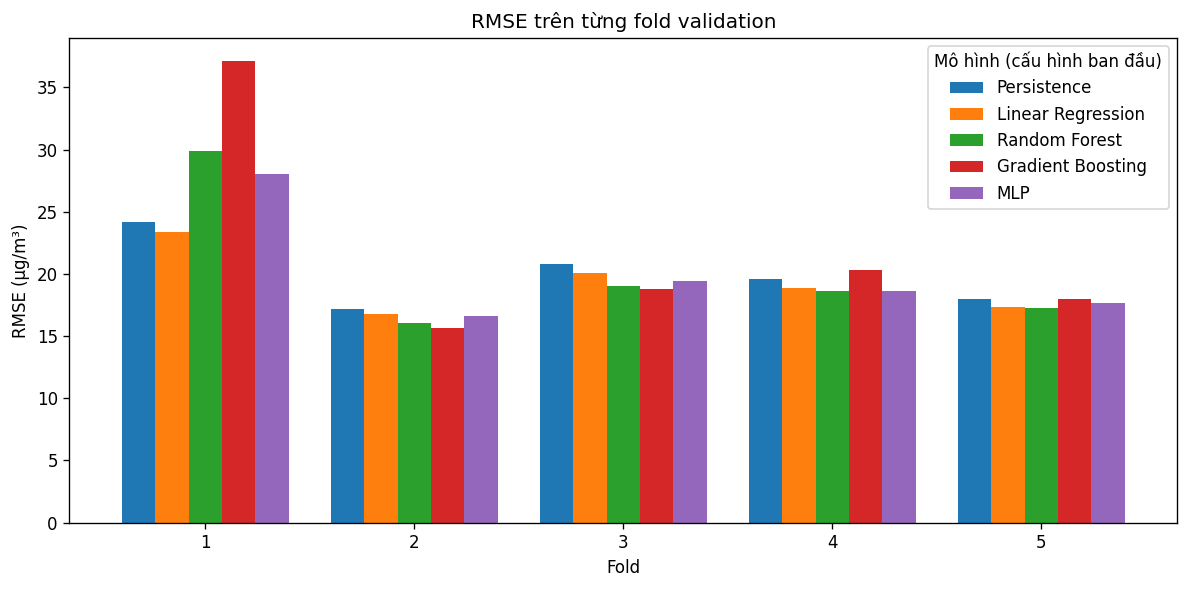

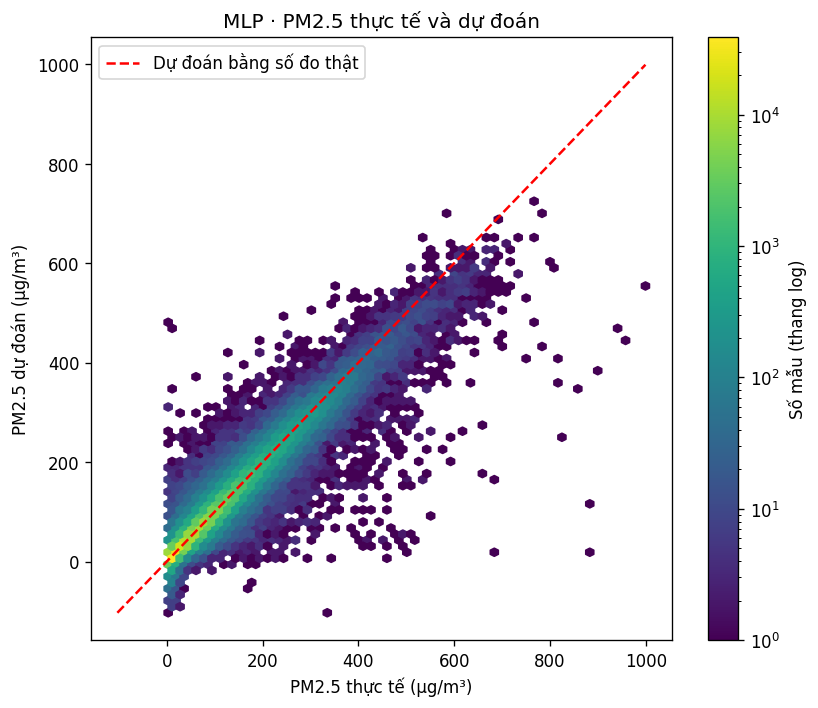

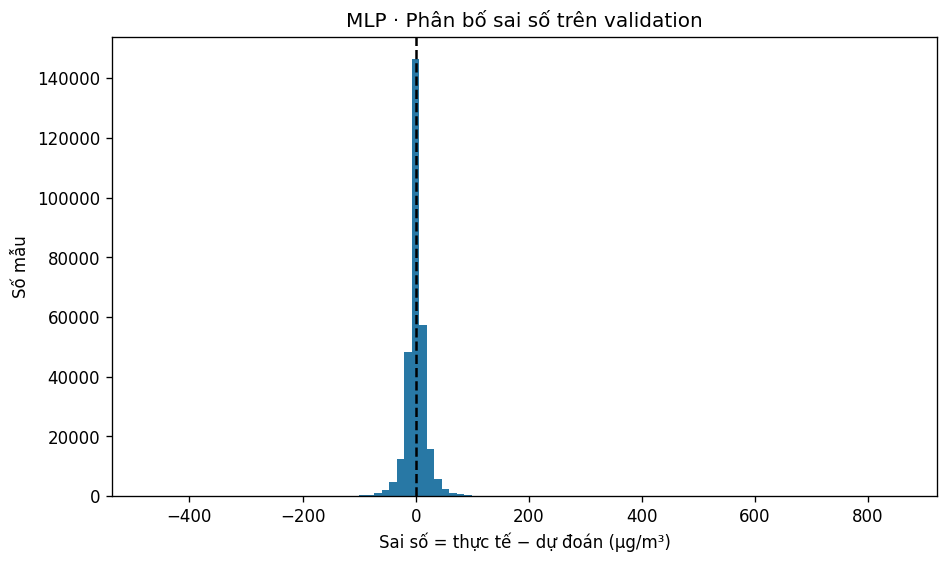

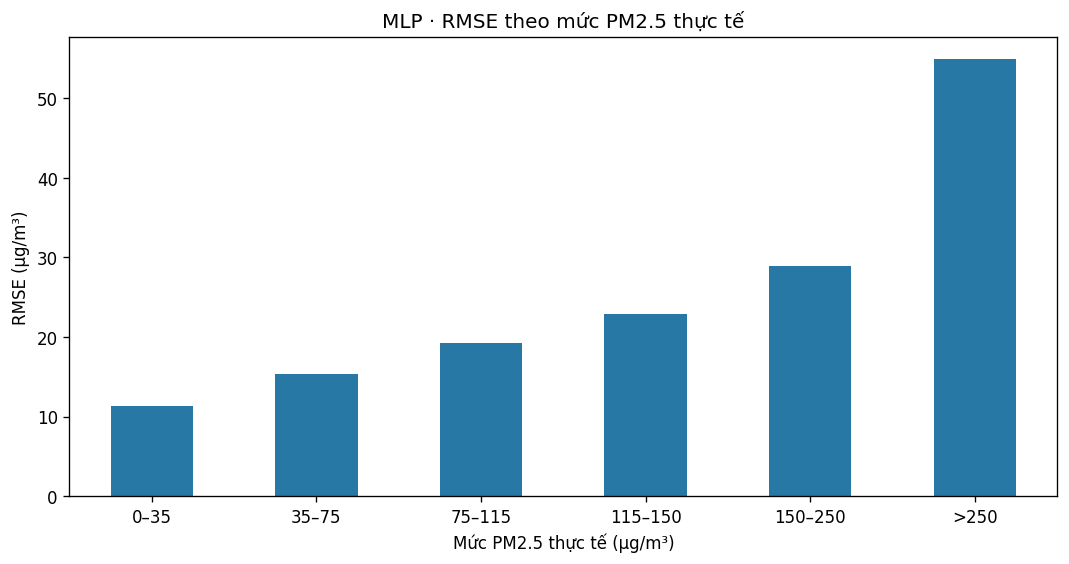

In [8]:
mlp_figures = {}

# 1. So sánh RMSE trên từng fold.
outputs_dir = project_root / "outputs"
rmse_by_fold = pd.DataFrame(index=mlp_cv_metrics["fold"])
baseline_path = outputs_dir / "baseline_comparison_merged.csv"
if baseline_path.is_file():
    baseline = pd.read_csv(baseline_path)
    baseline_folds = baseline.loc[baseline["scope"].eq("cv_fold")].copy()
    baseline_folds["fold"] = baseline_folds["group"].str.extract(r"(\d+)")[0].astype(int)
    baseline_folds = baseline_folds.set_index("fold")
    rmse_by_fold["Persistence"] = baseline_folds["rmse_P"]
    rmse_by_fold["Linear Regression"] = baseline_folds["rmse_LR"]

for model_name, filename in [
    ("Random Forest", "random_forest_cv_metrics.csv"),
    ("Gradient Boosting", "gradient_boosting_cv_metrics.csv"),
]:
    metrics_path = outputs_dir / filename
    if metrics_path.is_file():
        rmse_by_fold[model_name] = pd.read_csv(metrics_path).set_index("fold")["rmse"]

rmse_by_fold["MLP"] = mlp_cv_metrics.set_index("fold")["rmse"]
fig, ax = plt.subplots(figsize=(10, 5))
rmse_by_fold.plot.bar(ax=ax, width=0.8, rot=0)
ax.set(title="RMSE trên từng fold validation", xlabel="Fold", ylabel="RMSE (µg/m³)")
ax.legend(title="Mô hình (cấu hình ban đầu)")
mlp_figures["mlp_cv_rmse_by_fold.png"] = fig

# 2. Đặt dự đoán cạnh số đo thật.
fig, ax = plt.subplots(figsize=(7, 6))
density = ax.hexbin(
    mlp_oof["y_true"], mlp_oof["y_pred"],
    gridsize=60, bins="log", mincnt=1, cmap="viridis",
)
low = mlp_oof[["y_true", "y_pred"]].min().min()
high = mlp_oof[["y_true", "y_pred"]].max().max()
ax.plot([low, high], [low, high], "r--", label="Dự đoán bằng số đo thật")
ax.set(
    title="MLP · PM2.5 thực tế và dự đoán",
    xlabel="PM2.5 thực tế (µg/m³)",
    ylabel="PM2.5 dự đoán (µg/m³)",
)
fig.colorbar(density, ax=ax, label="Số mẫu (thang log)")
ax.legend()
mlp_figures["mlp_pred_vs_actual.png"] = fig

# 3. Xem phân bố sai số.
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(mlp_oof["residual"], bins=100, color="#2878a5")
ax.axvline(0, color="black", linestyle="--")
ax.set(
    title="MLP · Phân bố sai số trên validation",
    xlabel="Sai số = thực tế − dự đoán (µg/m³)",
    ylabel="Số mẫu",
)
mlp_figures["mlp_residuals.png"] = fig

# 4. Dùng cùng ngưỡng PM2.5 như notebook 04.
rmse_by_level = errors_by_level["rmse"]

fig, ax = plt.subplots(figsize=(9, 4.8))
rmse_by_level.plot.bar(ax=ax, rot=0, color="#2878a5")
ax.set(
    title="MLP · RMSE theo mức PM2.5 thực tế",
    xlabel="Mức PM2.5 thực tế (µg/m³)",
    ylabel="RMSE (µg/m³)",
)
mlp_figures["mlp_rmse_by_pm25_level.png"] = fig

for fig in mlp_figures.values():
    fig.tight_layout()
    with BytesIO() as buffer:
        fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
        display(Image(data=buffer.getvalue()))
    plt.close(fig)

## 9. Lưu đầu ra và kiểm tra nạp lại mô hình

Đặt `SAVE_ARTIFACTS = True` để huấn luyện mô hình cuối trên toàn bộ train + validation, xuất các file dưới đây và kiểm tra dự đoán trước và sau khi nạp lại mô hình. Đặt `SAVE_OOF = False` nếu muốn bỏ qua riêng CSV dự đoán chi tiết.

| Đầu ra | Nội dung |
|---|---|
| `models/mlp.joblib`, `models/mlp_metadata.json` | Pipeline đã huấn luyện, tham số, phiên bản thư viện, điểm và danh sách đầu ra |
| `outputs/mlp_cv_metrics.csv` | Điểm từng fold, RMSE train, chênh lệch và tỉ lệ RMSE |
| `outputs/mlp_cv_summary.csv` | Trung bình và độ lệch chuẩn của MAE, RMSE, R² |
| `outputs/mlp_error_by_group.csv` | Sai số theo mùa và mức PM2.5 |
| `outputs/mlp_validation_oof_predictions.csv` | Dự đoán từng mẫu validation, kèm fold, trạm, thời điểm, giá trị thực tế và sai số |
| `outputs/figures/mlp_*.png` | Bốn biểu đồ của mục 8 |
| `experiment_log.csv` | Dòng tổng hợp `mlp_cv5`, cập nhật theo mã thí nghiệm khi chạy lại |

In [9]:
SAVE_ARTIFACTS = True
SAVE_OOF = True

if SAVE_ARTIFACTS:
    outputs_dir = project_root / "outputs"
    models_dir = project_root / "models"
    outputs_dir.mkdir(exist_ok=True)
    models_dir.mkdir(exist_ok=True)
    figures_dir = outputs_dir / "figures"
    figures_dir.mkdir(exist_ok=True)

    figure_paths = []
    for filename, fig in mlp_figures.items():
        figure_path = figures_dir / filename
        fig.savefig(figure_path, dpi=150, bbox_inches="tight")
        figure_paths.append(figure_path)

    final_mlp = make_mlp()
    with threadpool_limits(limits=1):
        final_mlp.fit(X_tv, y_tv)

    model_path = models_dir / "mlp.joblib"
    metadata_path = models_dir / "mlp_metadata.json"
    metrics_path = outputs_dir / "mlp_cv_metrics.csv"
    summary_path = outputs_dir / "mlp_cv_summary.csv"
    error_path = outputs_dir / "mlp_error_by_group.csv"
    oof_path = outputs_dir / "mlp_validation_oof_predictions.csv"

    joblib.dump(final_mlp, model_path, compress=3)
    mlp_cv_metrics.to_csv(metrics_path, index=False, encoding="utf-8-sig")
    mlp_cv_summary.to_csv(summary_path, index=False, encoding="utf-8-sig")
    group_errors = pd.concat([
        errors_by_season.rename_axis("group").assign(group_type="season"),
        errors_by_level.rename_axis("group").assign(group_type="pm25_level"),
    ]).reset_index()
    group_errors[["group_type", "group", "n", "mean_pm25", "mae", "rmse", "mean_residual"]].to_csv(
        error_path, index=False, encoding="utf-8-sig"
    )
    saved_outputs = [model_path, metadata_path, metrics_path, summary_path, error_path, *figure_paths]
    if SAVE_OOF:
        mlp_oof.to_csv(oof_path, index=False, encoding="utf-8-sig")
        saved_outputs.append(oof_path)

    metadata = {
        "model": "MLPRegressor",
        "parameters": mlp_params,
        "sklearn_version": sklearn.__version__,
        "feature_columns": X_tv.columns.tolist(),
        "train_rows": len(X_tv),
        "test_evaluated": False,
        "validation_mean": mlp_scores,
        "final_fit_epochs": final_mlp.named_steps["model"].regressor_.n_iter_,
        "saved_outputs": [p.relative_to(project_root).as_posix() for p in saved_outputs],
    }
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

    new_log_row = {
        "experiment_id": "mlp_cv5",
        "model_name": "MLP",
        "dataset_version": log["dataset_version"].iloc[0],
        **mlp_scores,
        "notes": "Mean of 5 chronological validation folds. Fixed MLP (64, 32), "
                 "seed=42. Scaled numeric inputs and target, test not evaluated.",
    }
    log = pd.concat(
        [log.loc[log["experiment_id"].ne("mlp_cv5")], pd.DataFrame([new_log_row])],
        ignore_index=True,
    )
    log.to_csv(experiment_log, index=False, encoding="utf-8-sig")
    restored_mlp = joblib.load(model_path)
    sample = X_tv.iloc[:1000]
    with threadpool_limits(limits=1):
        np.testing.assert_allclose(restored_mlp.predict(sample), final_mlp.predict(sample))
    print("Kiểm tra nạp lại mô hình: PASS")
    print("Đã lưu:")
    for output_path in [*saved_outputs, experiment_log]:
        assert output_path.is_file() and output_path.stat().st_size > 0
        print("-", output_path.relative_to(project_root).as_posix())
else:
    print("Đặt SAVE_ARTIFACTS = True để xuất các file ở mục 9.")

Kiểm tra nạp lại mô hình: PASS
Đã lưu:
- models/mlp.joblib
- models/mlp_metadata.json
- outputs/mlp_cv_metrics.csv
- outputs/mlp_cv_summary.csv
- outputs/mlp_error_by_group.csv
- outputs/figures/mlp_cv_rmse_by_fold.png
- outputs/figures/mlp_pred_vs_actual.png
- outputs/figures/mlp_residuals.png
- outputs/figures/mlp_rmse_by_pm25_level.png
- outputs/mlp_validation_oof_predictions.csv
- experiment_log.csv


## 10. Kết luận

Kết luận tự cập nhật từ điểm của lần chạy hiện tại. Các số trong mục này mô tả cấu hình MLP ban đầu trên validation. Tập test vẫn dành cho đánh giá cuối sau khi chốt mô hình.

In [10]:
best_model = comparison.iloc[0]
mlp_rank = comparison.index[comparison["model_name"].eq("MLP")][0] + 1
largest_gap = mlp_cv_metrics.loc[mlp_cv_metrics["rmse_ratio"].idxmax()]
worst_season = errors_by_season["rmse"].idxmax()
worst_level = errors_by_level["rmse"].idxmax()
worst_level_metrics = errors_by_level.loc[worst_level]
hit_limit = mlp_cv_metrics.loc[mlp_cv_metrics["hit_iteration_limit"], "fold"].tolist()

print(f"1. Trung bình 5 fold: MAE {mlp_scores['mae']:.2f}, "
      f"RMSE {mlp_scores['rmse']:.2f} µg/m³, R² {mlp_scores['r2']:.4f}.")
print(f"2. MLP đứng {mlp_rank}/{len(comparison)} theo RMSE validation. "
      f"Đứng đầu bảng là {best_model['model_name']} (RMSE {best_model['rmse']:.2f}).")
print(f"3. Fold {int(largest_gap['fold'])} có tỉ lệ RMSE validation/train cao nhất "
      f"({largest_gap['rmse_ratio']:.2f} lần). Chênh lệch này cần được đọc cùng "
      "các mốc thời gian ở mục 6 trước khi kết luận học vẹt.")
print(f"4. Mùa sai nhiều nhất: {worst_season} "
      f"(RMSE {errors_by_season.loc[worst_season, 'rmse']:.2f} µg/m³). "
      f"Nhóm bụi sai nhiều nhất: {worst_level} µg/m³ "
      f"(RMSE {worst_level_metrics['rmse']:.2f} µg/m³, "
      f"sai lệch trung bình {worst_level_metrics['mean_residual']:+.2f} µg/m³).")
if hit_limit:
    print(f"5. Fold chạm giới hạn {mlp_params['max_iter']} vòng học: {hit_limit}.")
print("Kết quả trên tập test: chưa đánh giá.")

1. Trung bình 5 fold: MAE 11.73, RMSE 20.08 µg/m³, R² 0.9314.
2. MLP đứng 5/7 theo RMSE validation. Đứng đầu bảng là Random Forest Regressor - tuned (RMSE 19.18).
3. Fold 1 có tỉ lệ RMSE validation/train cao nhất (1.83 lần). Chênh lệch này cần được đọc cùng các mốc thời gian ở mục 6 trước khi kết luận học vẹt.
4. Mùa sai nhiều nhất: Đông (RMSE 27.83 µg/m³). Nhóm bụi sai nhiều nhất: >250 µg/m³ (RMSE 54.92 µg/m³, sai lệch trung bình +21.29 µg/m³).
5. Fold chạm giới hạn 60 vòng học: [1].
Kết quả trên tập test: chưa đánh giá.
